# Heart Disease UCI - Exploratory Data Analysis

Dataset: UCI Heart Disease (Cleveland subset, 303 patients, 13 clinical features). Target: `target` = 1 if any heart disease (original `num` > 0), else 0.

Goals: check data quality, understand distributions and class balance, and decide preprocessing for the model pipeline.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(style='whitegrid', palette='deep')
FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
df = pd.read_csv('../data/raw/heart.csv')
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 1. Data quality

In [2]:
print('Duplicate rows:', df.duplicated().sum())
missing = df.isna().sum().to_frame('missing')
missing['pct'] = (missing['missing'] / len(df) * 100).round(2)
missing[missing.missing > 0]

Duplicate rows: 0


,missing,pct
ca,4,1.32
thal,2,0.66


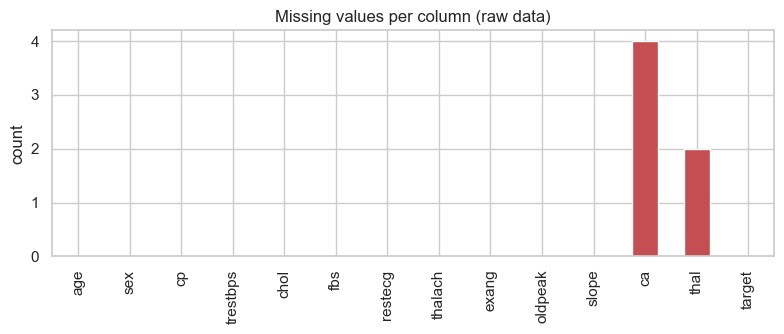

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
(df.isna().sum()).plot.bar(ax=ax, color='#c44e52')
ax.set_title('Missing values per column (raw data)'); ax.set_ylabel('count')
plt.tight_layout(); plt.savefig(FIG / 'missing_values.png', dpi=150); plt.show()

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


Only `ca` (4 rows) and `thal` (2 rows) contain missing values (<2% of rows). They are categorical codes, so the pipeline imputes them with the most frequent value; continuous columns use the median. No rows are dropped.

## 2. Class balance

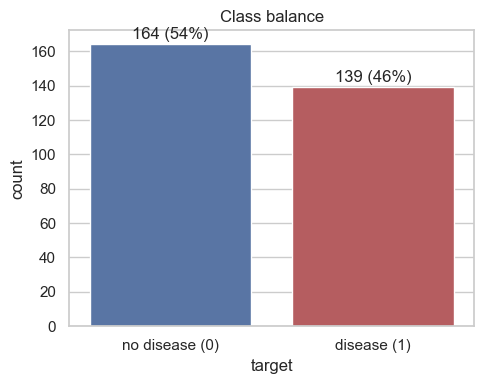

In [5]:
counts = df['target'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='target', hue='target', palette=['#4c72b0', '#c44e52'], legend=False, ax=ax)
for i, v in enumerate(counts): ax.text(i, v + 3, f'{v} ({v/len(df):.0%})', ha='center')
ax.set_xticks([0, 1], ['no disease (0)', 'disease (1)']); ax.set_title('Class balance')
plt.tight_layout(); plt.savefig(FIG / 'class_balance.png', dpi=150); plt.show()

The classes are close to balanced (~54% / 46%), so accuracy is meaningful, but we still report precision, recall and ROC-AUC and use stratified splits.

## 3. Distributions of continuous features

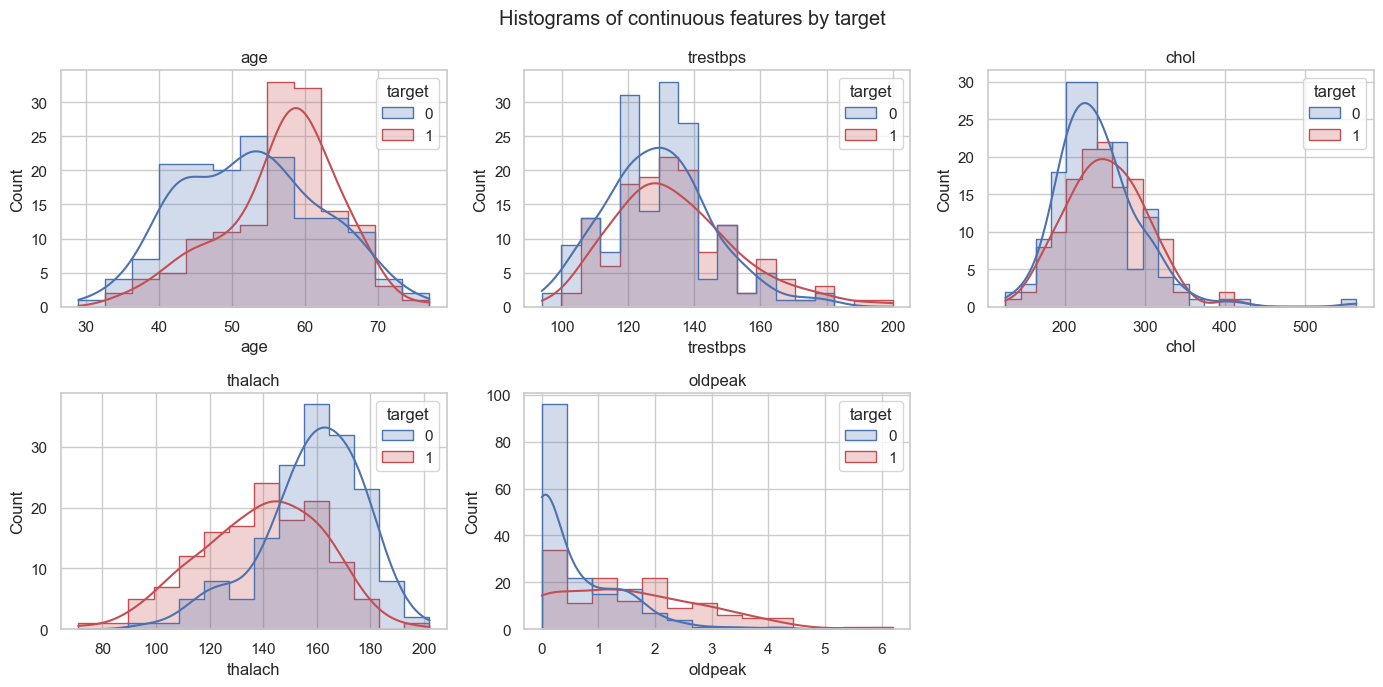

In [6]:
cont = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, cont):
    sns.histplot(data=df, x=col, hue='target', kde=True, element='step', ax=ax, palette=['#4c72b0', '#c44e52'])
    ax.set_title(col)
axes.flat[-1].axis('off')
fig.suptitle('Histograms of continuous features by target')
plt.tight_layout(); plt.savefig(FIG / 'histograms.png', dpi=150); plt.show()

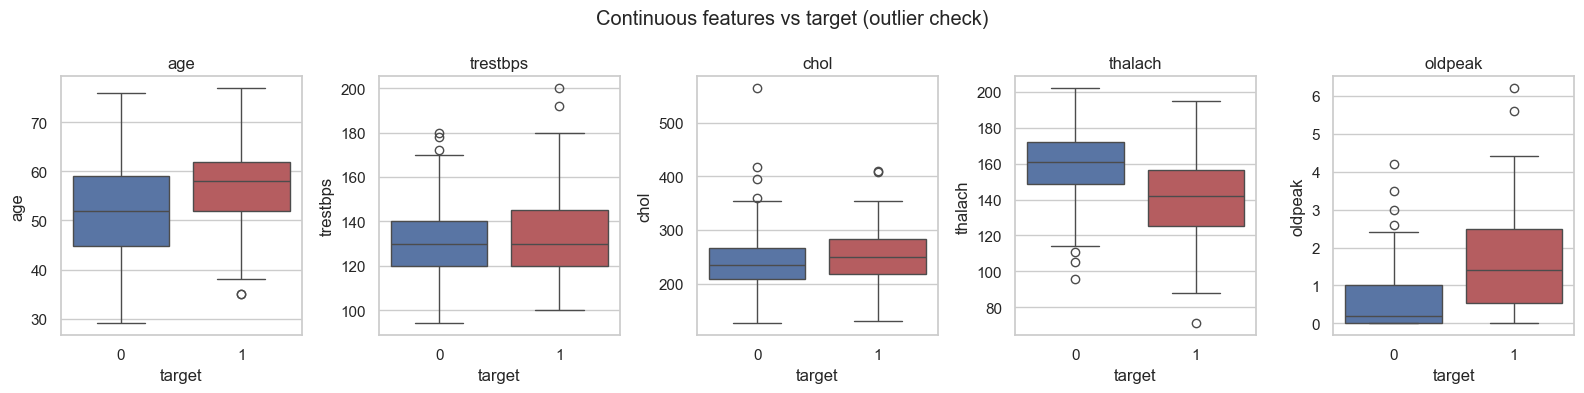

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, cont):
    sns.boxplot(data=df, x='target', y=col, hue='target', palette=['#4c72b0', '#c44e52'], legend=False, ax=ax)
    ax.set_title(col)
fig.suptitle('Continuous features vs target (outlier check)')
plt.tight_layout(); plt.savefig(FIG / 'boxplots.png', dpi=150); plt.show()

Patients with disease have lower maximum heart rate (`thalach`) and higher ST depression (`oldpeak`). `chol` and `trestbps` have a few high outliers, which is why we scale with a robust pipeline instead of dropping rows.

## 4. Categorical features vs target

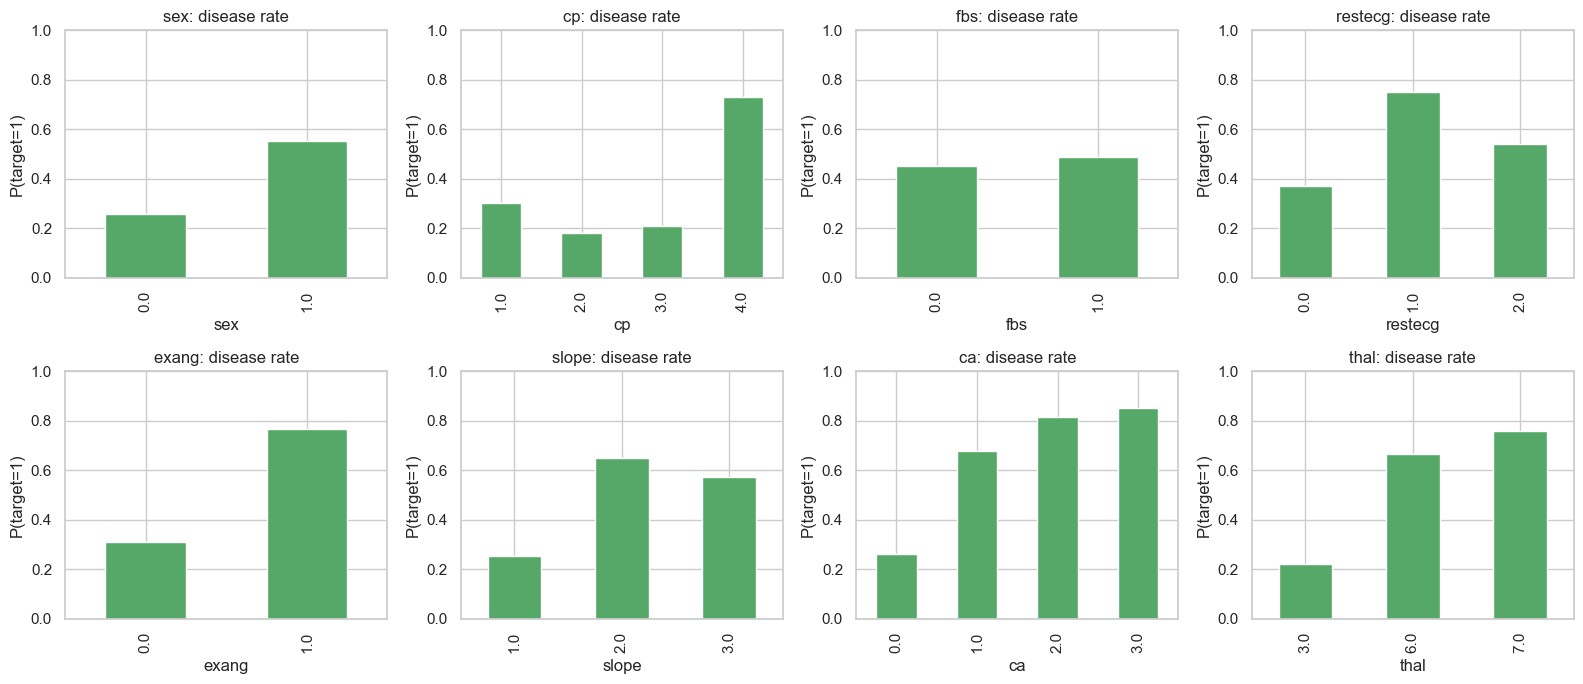

In [8]:
cat = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, cat):
    rate = df.groupby(col)['target'].mean()
    rate.plot.bar(ax=ax, color='#55a868')
    ax.set_title(f'{col}: disease rate'); ax.set_ylim(0, 1); ax.set_ylabel('P(target=1)')
plt.tight_layout(); plt.savefig(FIG / 'categorical_disease_rate.png', dpi=150); plt.show()

Disease rate changes sharply across `cp` (asymptomatic chest pain = type 4), `ca`, `thal` and `exang`, and the codes are not ordinal, so they are one-hot encoded in the pipeline.

## 5. Correlations

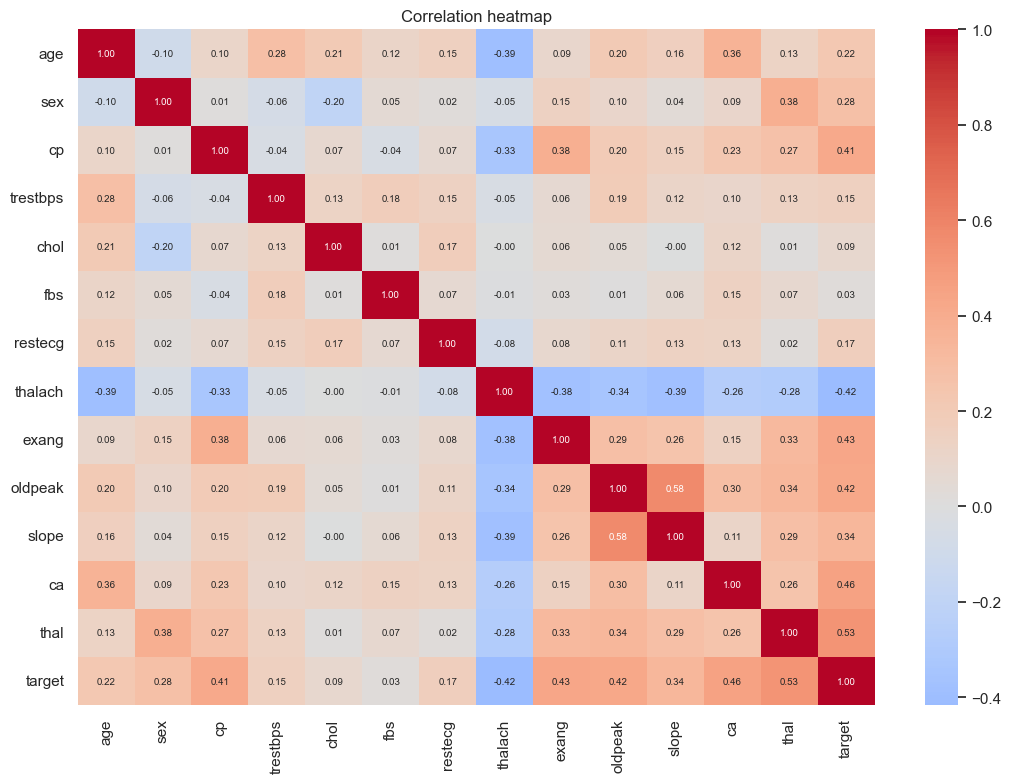

In [9]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation heatmap'); plt.tight_layout(); plt.savefig(FIG / 'correlation_heatmap.png', dpi=150); plt.show()

In [10]:
df.corr(numeric_only=True)['target'].drop('target').sort_values(key=abs, ascending=False).round(3)

thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
thalach    -0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
Name: target, dtype: float64

## 6. Preprocessing decisions

| Group | Columns | Steps |
|---|---|---|
| Continuous | age, trestbps, chol, thalach, oldpeak | median impute, StandardScaler |
| Binary | sex, fbs, exang | most-frequent impute |
| Categorical | cp, restecg, slope, ca, thal | most-frequent impute, OneHotEncoder |

All steps live in one scikit-learn `ColumnTransformer` (`src/preprocess.py`) that is saved inside the model pipeline, so training and serving apply identical transformations.